# Fig. 1 Static diamond chain: bulk bands and finite chain

Data for panels **b)** and **d)** of Fig. 1. Panels a) and c) are schematics and are not reproduced.

- **b)** Bulk bands $E(k)$ for $\phi = 0,\ 3\pi/4,\ \pi$ ($J = 1$).
- **d)** Spectrum of a finite chain with $N = 6$ cells, open ($3N$ sites) and closed ($3N+1$ sites) end, vs $\phi$, together with the bulk bands (shaded).

Output: `Data/Fig01_bulk_bands.npz`, `Data/Fig01_finite_chain_vs_flux.npz`

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parents[1]                 # .../paper_reproduction
DATA = ROOT / 'Data'

from diamond_chain import bulk_bands, finite_chain
from data_io import save_data

## Bulk bands for three values of the flux

In [2]:
J = 1.0
kvals = np.linspace(-np.pi, np.pi, 601)
phivals = np.array([0, 3 * np.pi / 4, np.pi])

bands = np.array([bulk_bands(kvals, phi, J) for phi in phivals])   # (phi, band, k)

save_data(DATA / 'Fig01_bulk_bands.npz', parameters={'J': J},
          kvals=kvals, phivals=phivals, bands=bands)

Saved Data/Fig01_bulk_bands.npz: kvals, phivals, bands


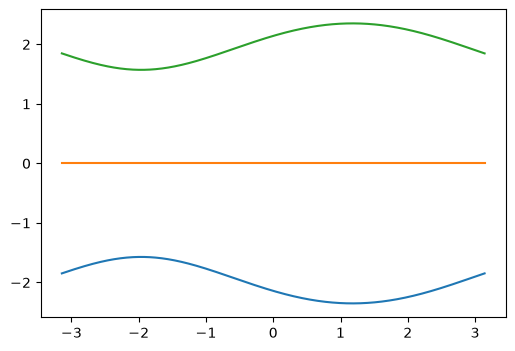

In [3]:
fig, ax = plt.subplots(1, 1, figsize=(6, 4))

for i in range(3):
    ax.plot(kvals, bands[1, i], color=f'C{i}', label=rf'$\phi = {phivals[i]:.2f}$')

## Finite chain (open vs closed end) as a function of the flux

In [4]:
J = 1.0
Ncells = 6
kvals = np.linspace(-np.pi, np.pi, 601)
phivals = np.linspace(0, np.pi, 200)

bands_phi = np.array([bulk_bands(kvals, phi, J) for phi in phivals])   # (phi, band, k)
E_open = np.array([np.linalg.eigvalsh(finite_chain(Ncells, phi, J, ending='open')) for phi in phivals])
E_closed = np.array([np.linalg.eigvalsh(finite_chain(Ncells, phi, J, ending='closed')) for phi in phivals])

save_data(DATA / 'Fig01_finite_chain_vs_flux.npz', parameters={'J': J, 'Ncells': Ncells},
          phivals=phivals, band_max=bands_phi.max(axis=2), band_min=bands_phi.min(axis=2),
          E_open=E_open, E_closed=E_closed)

Saved Data/Fig01_finite_chain_vs_flux.npz: phivals, band_max, band_min, E_open, E_closed
